In [1]:
from pathlib import Path
import json

parent_dir = Path.cwd().parents[1] 

file_path = parent_dir / "Dataset" / "research_abstracts.json"

with open(file_path, 'r', encoding="utf-8")as f:
    data = json.load(f)

print(data)


{'DOI': {'0': '10.1155/2021/1071145', '1': '10.1007/s43546-022-00384-2', '2': '10.1002/for.2667', '3': '10.1007/s42973-021-00091-x', '4': '10.1007/s40258-012-0003-z', '5': '10.1136/tc-2021-057232', '6': '10.1016/j.ssresearch.2019.102351', '7': '10.1080/02664763.2020.1732885', '8': '10.1097/01.mlr.0000118873.10396.fc', '9': '10.1016/j.mex.2021.101226', '10': '10.1038/s41598-020-64506-2', '11': '10.1371/journal.pone.0237672', '12': '10.2139/ssrn.3042952', '13': 'https://ssrn.com/abstract=1557280', '14': '10.1016/j.cbrev.2017.01.001', '15': '10.23917/jep.v5i1.4030', '16': '10.1109/cec.2007.4424790', '17': '10.1007/s12197-016-9354-x', '18': '10.1080/1331677x.2017.1314826', '19': '10.1111/j.1467-985x.2012.01061.x', '20': '10.1109/inocon57975.2023.10101073', '21': '10.1109/isitia.2017.8124101', '22': '10.1002/jae.2784', '23': '10.1080/13504850701578835', '24': '10.18356/df5e9f55-en', '25': '10.1162/003465303772815952', '26': '10.2139/ssrn.1016574', '27': '10.17016/ifdp.2003.780', '28': '10.2

In [2]:
data = data["Abstract"]

display(data)

{'0': "Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. In this sense, the forecast of inflation rate is of great significance. The existing literature mainly uses linear models such as autoregressive (AR) and vector autoregressive (VAR) models to predict the inflation rate. The nonlinear relationship between variables and the mining of historical data information are relatively lacking. Therefore, the prediction strategies and accuracy of the existing literature need to be improved. The predictive model designed in deep learning can fully mine the nonlinear relationship between variables and process complex long-term time series dynamic information, thereby making up for the deficiencies 

In [3]:
import pandas as pd

df = pd.Series(data).to_frame(name='Abstract')

display(df)

,Abstract
0,Forward-looking forecasting of the inflation r...
1,Our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ..."
4,BackgroundGame theory is useful for identifyin...
...,...
1133,Concluding remarksWhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web..."
1136,"Summary EOR projects, notably CO2 floods, are ..."


In [4]:
import re

pattern = r'[^a-zA-Z\s]'

df['clean_Abstract'] = df['Abstract'].str.replace(pattern, '', regex=True)

In [5]:
print(df["clean_Abstract"].isna().sum())

0


In [6]:
df = df.dropna()
df.dropna(subset=['clean_Abstract'], inplace=True)


In [7]:
df

,Abstract,clean_Abstract
0,Forward-looking forecasting of the inflation r...,Forwardlooking forecasting of the inflation ra...
1,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ...",In this paper I use a simple SIR Macro model t...
4,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...
...,...,...
1133,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...,HighDimensional Dynamic Factor Models have the...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",Francesca Gino Erin L Krupka Roberto A Weber D...
1136,"Summary EOR projects, notably CO2 floods, are ...",Summary EOR projects notably CO floods are the...


In [8]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ponts\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ponts\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [9]:
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = text.split()
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    return " ".join(lemmatized_words)

In [10]:
df['text_lemmatized'] = df['clean_Abstract'].apply(lemmatize_text)

In [11]:
df

,Abstract,clean_Abstract,text_lemmatized
0,Forward-looking forecasting of the inflation r...,Forwardlooking forecasting of the inflation ra...,Forwardlooking forecasting of the inflation ra...
1,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ...",In this paper I use a simple SIR Macro model t...,In this paper I use a simple SIR Macro model t...
4,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...
...,...,...,...
1133,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...,HighDimensional Dynamic Factor Models have the...,HighDimensional Dynamic Factor Models have the...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",Francesca Gino Erin L Krupka Roberto A Weber D...,Francesca Gino Erin L Krupka Roberto A Weber D...
1136,"Summary EOR projects, notably CO2 floods, are ...",Summary EOR projects notably CO floods are the...,Summary EOR project notably CO flood are the n...


In [12]:
# Replace whitespace-only strings with actual NaN
df['clean_Abstract'] = df['clean_Abstract'].replace(r'^\s*$', pd.NA, regex=True)
df['text_lemmatized'] = df['text_lemmatized'].replace(r'^\s*$', pd.NA, regex=True)

# Drop rows with empty values in either column
df = df.dropna(subset=['clean_Abstract', 'text_lemmatized'])

# Drop rows where the "word" is too short to be meaningful (e.g. 1-2 chars)
df = df[df['clean_Abstract'].str.len() > 2]

df = df.reset_index(drop=True)


In [13]:
df

,Abstract,clean_Abstract,text_lemmatized
0,Forward-looking forecasting of the inflation r...,Forwardlooking forecasting of the inflation ra...,Forwardlooking forecasting of the inflation ra...
1,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...
2,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...
3,"In this paper, I use a simple SIR Macro model ...",In this paper I use a simple SIR Macro model t...,In this paper I use a simple SIR Macro model t...
4,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...
...,...,...,...
1133,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...
1134,High-Dimensional Dynamic Factor Models have th...,HighDimensional Dynamic Factor Models have the...,HighDimensional Dynamic Factor Models have the...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",Francesca Gino Erin L Krupka Roberto A Weber D...,Francesca Gino Erin L Krupka Roberto A Weber D...
1136,"Summary EOR projects, notably CO2 floods, are ...",Summary EOR projects notably CO floods are the...,Summary EOR project notably CO flood are the n...


In [14]:
# nltk.download('words')
# from nltk.corpus import words

# english_vocab = set(w.lower() for w in words.words())

# df = df[df['text_lemmatized'].str.lower().isin(english_vocab)]

In [15]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df['stop_removed'] = df['text_lemmatized'].apply(
    lambda x: ' '.join([w for w in x.split() if w.lower() not in ENGLISH_STOP_WORDS])
)

In [16]:
df

,Abstract,clean_Abstract,text_lemmatized,stop_removed
0,Forward-looking forecasting of the inflation r...,Forwardlooking forecasting of the inflation ra...,Forwardlooking forecasting of the inflation ra...,Forwardlooking forecasting inflation rate help...
1,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...,Our study examined the disaggregation of infla...,study examined disaggregation inflation compon...
2,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...,This paper develops a dynamic factor model tha...,paper develops dynamic factor model euro area ...
3,"In this paper, I use a simple SIR Macro model ...",In this paper I use a simple SIR Macro model t...,In this paper I use a simple SIR Macro model t...,paper use simple SIR Macro model examine Japan...
4,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...,BackgroundGame theory is useful for identifyin...,BackgroundGame theory useful identifying condi...
...,...,...,...,...
1133,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...,Concluding remarksWhile the final version of t...,Concluding remarksWhile final version Tax Refo...
1134,High-Dimensional Dynamic Factor Models have th...,HighDimensional Dynamic Factor Models have the...,HighDimensional Dynamic Factor Models have the...,HighDimensional Dynamic Factor Models origin m...
1135,"Francesca Gino, Erin L. Krupka, Roberto A. Web...",Francesca Gino Erin L Krupka Roberto A Weber D...,Francesca Gino Erin L Krupka Roberto A Weber D...,Francesca Gino Erin L Krupka Roberto Weber Doe...
1136,"Summary EOR projects, notably CO2 floods, are ...",Summary EOR projects notably CO floods are the...,Summary EOR project notably CO flood are the n...,Summary EOR project notably flood generation r...


In [17]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

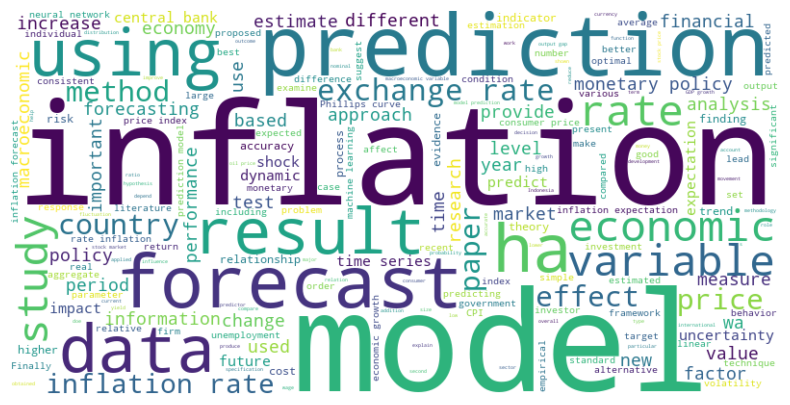

In [18]:
text_data = df["stop_removed"]

combined_string = " ".join(text_data)

wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color="white", 
    colormap="viridis"
).generate(combined_string)

# Display the word cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()